# Portfolio Optimization : modèle de Markowitz naïf

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from portfolio_optimization.allocation import (
    GMV_allocator,
    denoised_GMV_allocator,
    isoweighted_allocator,
    ledoit_wolf_GMV_allocator,
)
from portfolio_optimization.data_loader import (
    fetch_returns,
    get_empirical_moments,
)
from portfolio_optimization.evaluation import out_of_sample_evaluation
from portfolio_optimization.optimizer import (
    solve_efficient_border,
)


In [23]:
START = pd.Timestamp("2023-01-01")
END = pd.Timestamp("2024-01-01")

# Récupération des données

In [24]:
df_expected_returns, df_covariance = get_empirical_moments(
    start=START,
    end=END,
)

[*********************100%***********************]  100 of 100 completed


# Résolution de la frontière efficiente

In [25]:
optimal_allocations, efficient_border_expected_returns, efficient_border_sigma = solve_efficient_border(
    df_expected_returns=df_expected_returns,
    df_covariance=df_covariance
)

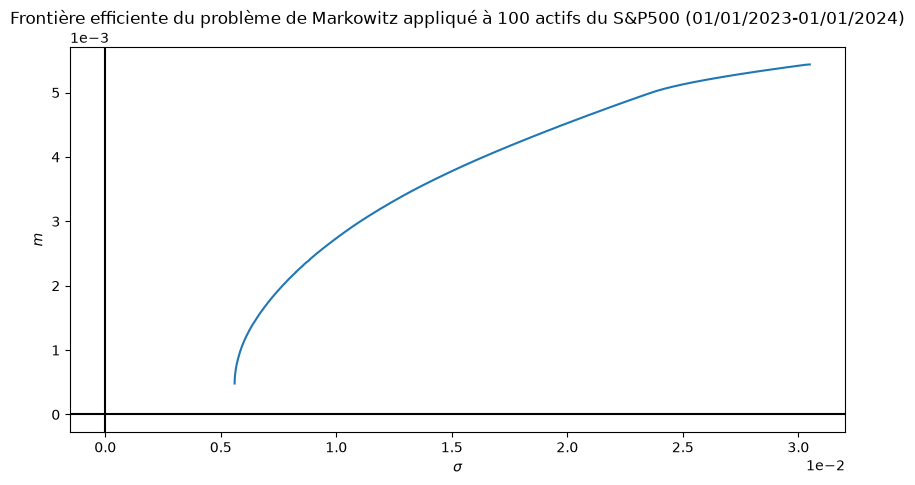

In [26]:
fig, ax = plt.subplots()

fig.set_size_inches(10, 5)

ax.plot(
    efficient_border_sigma,
    efficient_border_expected_returns,
)
ax.set_xlabel(r"$\sigma$")
ax.set_ylabel(r"$m$")
ax.set_title(f"Frontière efficiente du problème de Markowitz appliqué à 100 actifs du S&P500 ({START.strftime('%d/%m/%Y')}-{END.strftime('%d/%m/%Y')})")
ax.axhline(0, color="black")
ax.axvline(0, color="black")
ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

plt.show()

## Hyper-concentration des poids

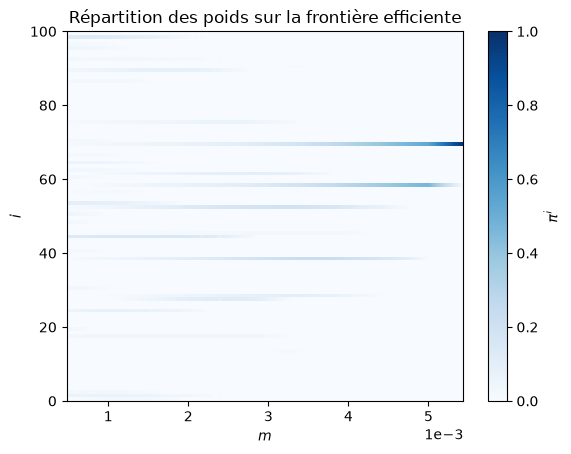

In [27]:
fig, ax = plt.subplots()

im = ax.matshow(
    optimal_allocations.T,
    extent=[
        efficient_border_expected_returns[0],
        efficient_border_expected_returns[-1],
        0,
        optimal_allocations.shape[1],
    ],
    aspect='auto',
    origin='lower',
    cmap='Blues',
    vmin=0,
    vmax=1,
)
ax.set_xlabel("$m$")
ax.xaxis.tick_bottom()
ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
ax.set_ylabel("$i$")
ax.set_title("Répartition des poids sur la frontière efficiente")
fig.colorbar(im, ax=ax, label=r"$\pi^i$")
plt.show()

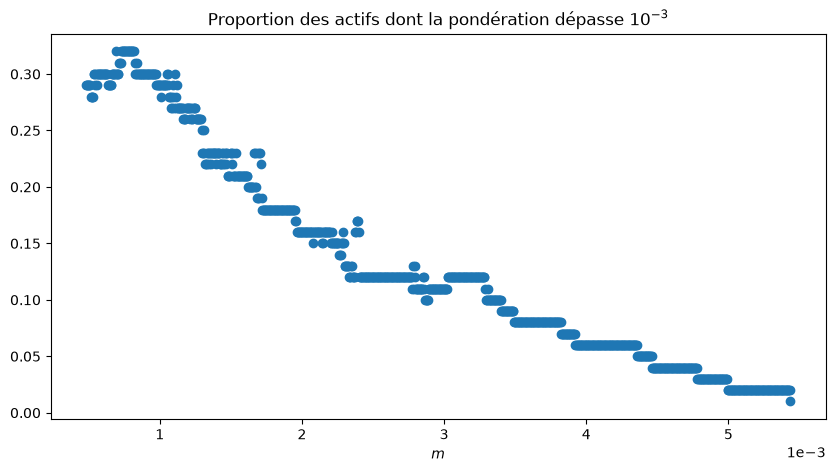

In [28]:
fig, ax = plt.subplots()

fig.set_size_inches(10, 5)

ax.scatter(
    efficient_border_expected_returns,
    [
        sum(
            1
            for weight in optimal_allocation
            if weight >= 1e-3
        )/optimal_allocation.shape[0]
        for optimal_allocation in optimal_allocations
    ]
)
ax.set_xlabel("$m$")
ax.set_title("Proportion des actifs dont la pondération dépasse $10^{-3}$")
ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))

plt.show()

## Instabilité *out-of-sample*

### Récupération des données

In [29]:
START = pd.Timestamp("2018-01-01")
END = pd.Timestamp("2024-01-01")
T = 252
DELTA_T = 21

In [30]:
df_returns = fetch_returns(start=START, end=END)

[*********************100%***********************]  100 of 100 completed


## Evaluation out-of-sample

In [31]:
GMV_evaluation = out_of_sample_evaluation(
    df_returns=df_returns,
    allocator=GMV_allocator,
    delta_days=DELTA_T,
    sample_window_size=T,
)

### Allure du turnover

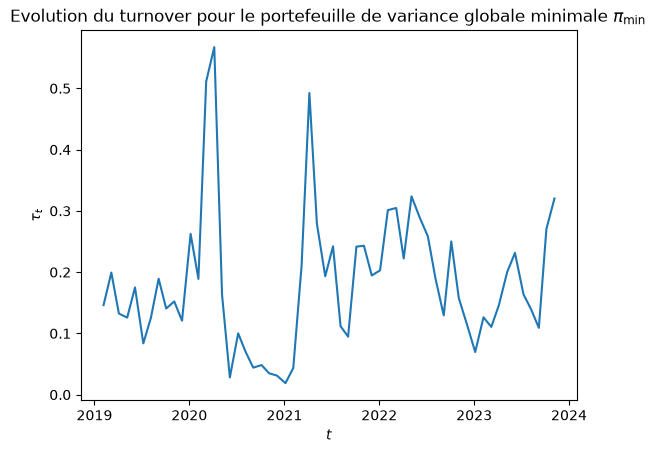

In [32]:
fig, ax = plt.subplots()

ax.plot(GMV_evaluation.rebalancing_dates[1:], GMV_evaluation.turnover[1:])
ax.set_title(r"Evolution du turnover pour le portefeuille de variance globale minimale $\pi_{\min}$")
ax.set_xlabel("$t$")
ax.set_ylabel(r"$\tau_t$")
plt.show()

### Comparaison de la volatilité prédite et de la volatilité réalisée

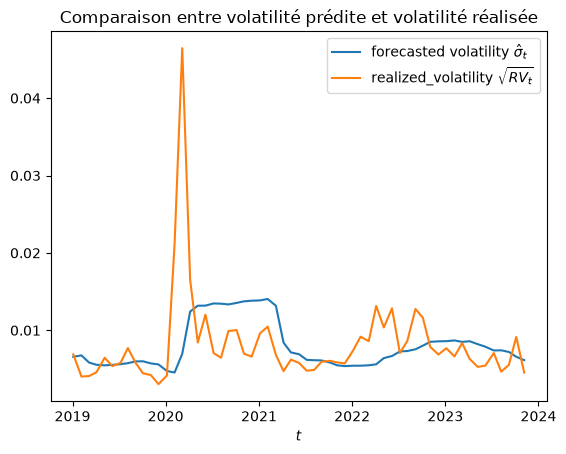

In [33]:
fig, ax = plt.subplots()

ax.plot(GMV_evaluation.rebalancing_dates, GMV_evaluation.forecasted_volatility, label=r"forecasted volatility $\hat{\sigma}_t$")
ax.plot(GMV_evaluation.rebalancing_dates, GMV_evaluation.realized_volatility, label=r"realized_volatility $\sqrt{RV_t}$")
ax.legend()
ax.set_title(r"Comparaison entre volatilité prédite et volatilité réalisée")
ax.set_xlabel("$t$")
plt.show()

### Instabilité de la composition du portefeuille 

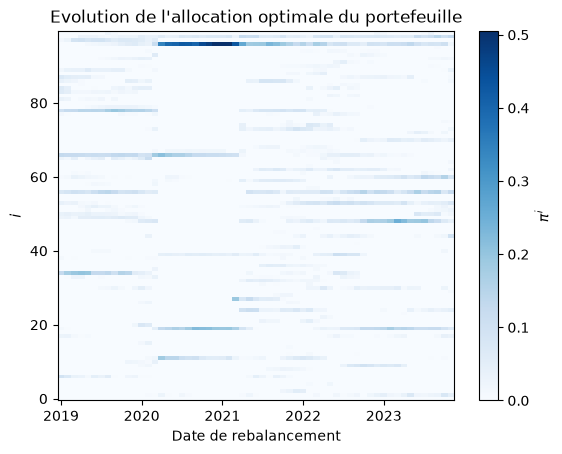

In [34]:
fig, ax = plt.subplots()
# fig.set_size_inches(15, 5)

im = ax.matshow(
    GMV_evaluation.allocations.T,
    aspect='auto',
    origin='lower',
    cmap='Blues',
    vmin=0,
    vmax=GMV_evaluation.allocations.max(),
)
tick_indices = np.arange(0, len(GMV_evaluation.rebalancing_dates), 12)
tick_labels = GMV_evaluation.rebalancing_dates[tick_indices].strftime("%Y")

ax.set_ylabel("$i$")
ax.xaxis.tick_bottom()
ax.set_xticks(tick_indices)
ax.set_xticklabels(tick_labels)
ax.set_xlabel("Date de rebalancement")
ax.set_title("Evolution de l'allocation optimale du portefeuille")
fig.colorbar(im, ax=ax, label=r"$\pi^i$")
plt.show()

### Comparaison de stratégies

In [35]:
evaluations = {
    "GMV": GMV_evaluation
}

for method, allocator in zip(
    ["isoweighted", "denoised", "ledoit_wolf"],
    [isoweighted_allocator, denoised_GMV_allocator, ledoit_wolf_GMV_allocator]
):
    evaluations[method] = out_of_sample_evaluation(
        df_returns=df_returns,
        allocator=allocator,
        delta_days=DELTA_T,
        sample_window_size=T
    )

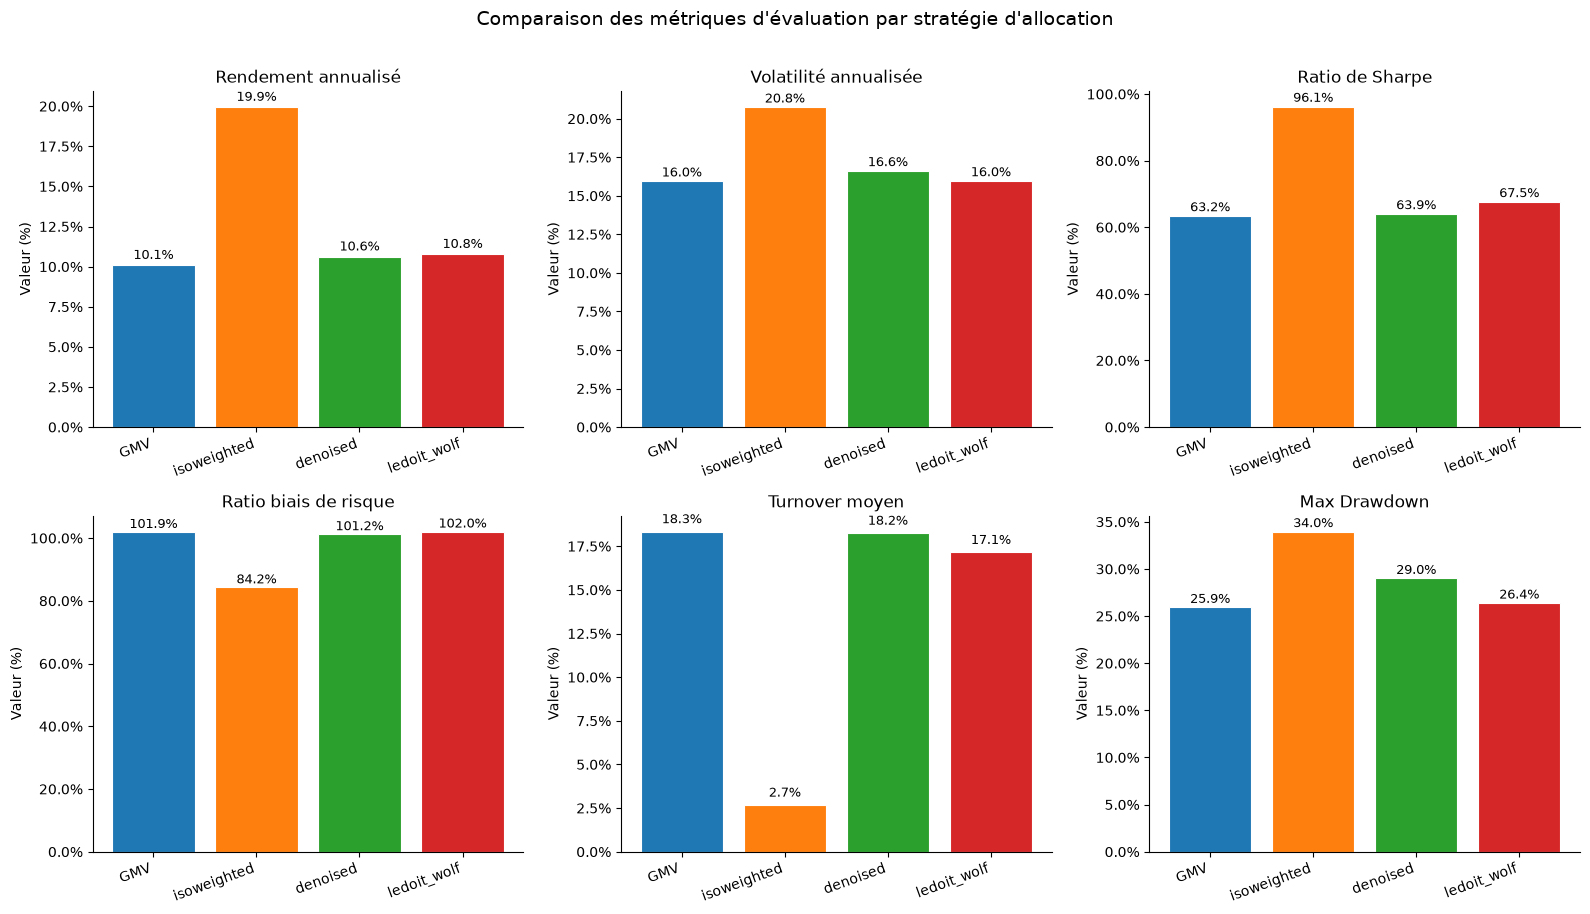

In [36]:
df_metrics = pd.DataFrame({method: eval.summarize() for method, eval in evaluations.items()}).T

metrics_labels = {
    "arithmetic_annualized_return": "Rendement annualisé",
    "annualized_volatility": "Volatilité annualisée",
    "annualized_sharpe": "Ratio de Sharpe",
    "risk_bias_ratio": "Ratio biais de risque",
    "mean_turnover": "Turnover moyen",
    "max_drawdown": "Max Drawdown",
}

methods = list(df_metrics.index)
n_metrics = len(metrics_labels)
n_methods = len(methods)

colors = plt.cm.tab10.colors[:n_methods]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (metric_key, metric_label) in zip(axes, metrics_labels.items()):
    values = df_metrics[metric_key].values
    bars = ax.bar(methods, values, color=colors, edgecolor="white", linewidth=0.8)
    ax.set_title(metric_label, fontsize=12)
    ax.set_ylabel("Valeur (%)", fontsize=10)
    ax.set_xticks(range(n_methods))
    ax.set_xticklabels(methods, rotation=20, ha="right", fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
    ax.spines[["top", "right"]].set_visible(False)
    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (max(values) - min(values)) * 0.02,
            f"{val:.1%}",
            ha="center", va="bottom", fontsize=9
        )

fig.suptitle("Comparaison des métriques d'évaluation par stratégie d'allocation", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()